# Fig. 5d-n: EnrichMap (null) across platforms

A showcase of EnrichMap (null) on Xenium breast cancer (Fig. 5d-f), MERFISH hypothalamus (Fig. 5g-j, scored per section
with `batch_key="batch"`) and imaging mass cytometry (Fig. 5k-n). Single-cell data are smoothed on the Delaunay graph
with two rings. ED10: null-model diagnostics on low-plex panels. Source data are saved as CSV next to each figure.

In [1]:
import os
import warnings

os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")

In [2]:
import scanpy as sc
import squidpy as sq
import pandas as pd
import numpy as np
import enrichmap as em
import matplotlib.pyplot as plt
import seaborn as sns
import re

from functools import partial
from scipy.sparse import issparse
from scipy.stats import mannwhitneyu, rankdata

In [3]:
sc.set_figure_params(frameon=False, fontsize=6)
sc.settings._vector_friendly = False
plt.rcParams["axes.grid"] = False

In [4]:
# set working directory
# repository root (the folder containing `notebooks/`); safe to re-run this cell
import sys
project_dir = os.getcwd()
if os.path.basename(project_dir) == "notebooks":
    project_dir = os.path.dirname(project_dir)
project_dir += "/"
sys.path.insert(0, project_dir + "notebooks")  # helpers.py and score_signatures.py
working_dir = project_dir
os.chdir(working_dir)

# set figure directory
figure_dir = working_dir + "figures/"
os.makedirs(figure_dir, exist_ok=True)

# processed data directory
processed_data = project_dir + "processed_data/"

# source data directory
source_dir = working_dir + "source_data/"
os.makedirs(source_dir, exist_ok=True)

In [5]:
colours = {"EnrichMap (null)": "#2f0bdf"}

In [6]:
from helpers import (
    enrichmap_null_control_sets,
    platform_binary_calls,
    platform_block_bootstrap,
    platform_ci95,
    platform_delaunay_weights,
    platform_kmeans_blocks,
    platform_map_table,
    platform_morans_i,
    platform_gearys_c,
    platform_plot_roc,
    platform_plot_violins,
    platform_run_p_empirical,
    platform_run_score,
    platform_tpr_at_fpr,
    pseudobulk_deseq2_signature,
    set_box_ratio,
)

In [7]:
# 1. Load data (03_xenium_platform, 04_merfish_platform, 10_masscytometry_platform_deg)
# xenium: xe_rep1, raw counts
adata_xe = sc.read_h5ad(project_dir + "xenium_aligned_ductal_invasive.h5ad")
adata_xe.X = adata_xe.layers["counts"].copy()

# merfish: 12 Bregma sections, each rescaled to [0, 1] in obsm["spatial"]; integer counts
adata_mf = sq.datasets.merfish(path=project_dir + "data/anndata/merfish.h5ad")
adata_mf.X = adata_mf.X.astype(int)

# imc: raw intensities rounded to integers
adata_imc = sq.datasets.imc(path=project_dir + "data/anndata/imc.h5ad")
adata_imc.X = adata_imc.raw.X.round().astype(np.int64).copy()

# labels and coordinates
cluster = adata_xe.obs["Cluster"].astype(str).values
is_dcis = np.isin(cluster, ["DCIS_1", "DCIS_2"])
is_cd8 = cluster == "CD8+_T_Cells"
xy_xe = np.asarray(adata_xe.obsm["spatial"], float)

cell_class = adata_mf.obs["Cell_class"].astype(str).values
is_ep = cell_class == "Ependymal"
section_mf = adata_mf.obs["batch"].astype(str).values
bregma9 = (adata_mf.obs["Bregma"] == -9).values  # section shown in Fig. 5g-h
xy_mf = np.asarray(adata_mf.obsm["spatial"], float)
xy_mf_um = adata_mf.obs[["Centroid_X", "Centroid_Y"]].values.astype(float)

cell_type = adata_imc.obs["cell type"].astype(str).values
is_basal = cell_type == "basal CK tumor cell"
is_t = cell_type == "T cells"
xy_imc = np.asarray(adata_imc.obsm["spatial"], float)

In [8]:
# 2. Pseudo-bulk DESeq2 signatures (03_xenium_platform cells 7-8, 04_merfish_platform cell 7,
# 10_masscytometry_platform_deg cells 7-8)
signatures_xe = {
    "DCIS": pseudobulk_deseq2_signature(adata_xe, is_dcis, "DCIS", 0.01, 2, 10),
    "CD8+_T_Cells": pseudobulk_deseq2_signature(adata_xe, is_cd8, "CD8+_T_Cells", 0.01, 1, 10),
}
signatures_mf = {"Ependymal": pseudobulk_deseq2_signature(adata_mf, is_ep, "Ependymal", 0.01, 2.5, 20)}
signatures_imc = {
    "Basal tumour": pseudobulk_deseq2_signature(adata_imc, is_basal, "Basal tumour", 0.05, 0.5, 5),
    "T cell": pseudobulk_deseq2_signature(adata_imc, is_t, "T cells", 0.05, 0.5, 5),
}

# log-normalisation
for adata in [adata_xe, adata_mf, adata_imc]:
    sc.pp.normalize_total(adata, target_sum=1e4)
    sc.pp.log1p(adata)

for sig, genes in {**signatures_xe, **signatures_mf, **signatures_imc}.items():
    print(f"{sig} ({len(genes)}): {', '.join(genes)}")

Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.00 seconds.

Fitting dispersions...
... done in 0.29 seconds.

Fitting dispersion trend curve...
... done in 0.02 seconds.

Fitting MAP dispersions...
... done in 0.25 seconds.

Fitting LFCs...
... done in 0.16 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 0 outlier genes.

Running Wald tests...
... done in 0.12 seconds.



Log2 fold change & Wald test p-value: group DCIS vs Rest
            baseMean  log2FoldChange     lfcSE       stat         pvalue  \
ABCC11  26323.906329        1.722172  0.040035  43.016278   0.000000e+00   
ACTA2   29184.898701        0.393836  0.047365   8.314922   9.181300e-17   
ACTG2   37468.888335        1.453935  0.043189  33.664219  1.931268e-248   
ADAM9   28192.909304        1.625794  0.040768  39.879427   0.000000e+00   
ADGRE5   2476.079041       -1.378854  0.060280 -22.874014  8.430943e-116   
...              ...             ...       ...        ...            ...   
VWF      4325.163452       -2.244736  0.059414 -37.781350   0.000000e+00   
WARS    12898.761215        1.113035  0.046178  24.103397  2.302880e-128   
ZEB1     3626.862481       -2.675863  0.110145 -24.293908  2.273602e-130   
ZEB2     9782.425485       -2.644346  0.051258 -51.588481   0.000000e+00   
ZNF562  19554.889956        2.077034  0.043403  47.854609   0.000000e+00   

                 padj  
ABCC11

Fitting size factors...
... done in 0.00 seconds.

Fitting dispersions...


Using None as control genes, passed at DeseqDataSet initialization


... done in 0.37 seconds.

Fitting dispersion trend curve...
... done in 0.03 seconds.

Fitting MAP dispersions...
... done in 0.27 seconds.

Fitting LFCs...
... done in 0.18 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 0 outlier genes.

Running Wald tests...
... done in 0.12 seconds.



... (3 outputs left out)

Fitting size factors...
... done in 0.00 seconds.

Fitting dispersions...
... done in 0.11 seconds.

Fitting dispersion trend curve...
... done in 0.03 seconds.

Fitting MAP dispersions...
... done in 0.11 seconds.

Fitting LFCs...
... done in 0.08 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 0 outlier genes.

Running Wald tests...
... done in 0.07 seconds.



Log2 fold change & Wald test p-value: group Basal tumour vs Rest
                            baseMean  log2FoldChange     lfcSE       stat  \
1021522Tm169Di EGFR       382.595488        0.110374  0.085940   1.284310   
1031747Er167Di ECadhe    1972.251591       -0.067032  0.041322  -1.622211   
112475Gd156Di Estroge       9.279842       -1.727014  0.805242  -2.144715   
117792Dy163Di GATA3         9.059566       -1.187348  0.774432  -1.533185   
1261726In113Di Histone   5524.902345       -0.189668  0.026668  -7.112275   
1441101Er168Di Ki67       132.426725        0.327421  0.145127   2.256108   
174864Nd148Di SMA         426.507511       -1.120575  0.101727 -11.015541   
1921755Sm149Di Vimenti    591.337971       -1.204518  0.096136 -12.529328   
198883Yb176Di cleaved     603.432667       -0.159341  0.072816  -2.188265   
201487Eu151Di cerbB      1468.224849        0.179951  0.046317   3.885177   
234832Lu175Di panCyto    1857.834245        2.342062  0.176329  13.282336   
3111576Nd14

Fitting size factors...
... done in 0.00 seconds.

Fitting dispersions...
... done in 0.09 seconds.

Fitting dispersion trend curve...
... done in 0.01 seconds.

Fitting MAP dispersions...
... done in 0.09 seconds.

Fitting LFCs...
... done in 0.08 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 0 outlier genes.

Running Wald tests...
... done in 0.06 seconds.



Log2 fold change & Wald test p-value: group T cells vs Rest
                            baseMean  log2FoldChange     lfcSE       stat  \
1021522Tm169Di EGFR       240.762772       -0.489309  0.182014  -2.688301   
1031747Er167Di ECadhe    1224.301469       -0.752304  0.122780  -6.127261   
112475Gd156Di Estroge       6.587552       -1.834527  1.057707  -1.734439   
117792Dy163Di GATA3         7.448554       -0.614450  0.793152  -0.774694   
1261726In113Di Histone   3971.993828       -0.311295  0.134459  -2.315163   
1441101Er168Di Ki67        55.273955       -2.395810  0.490644  -4.882995   
174864Nd148Di SMA         868.365524        1.883882  0.168633  11.171511   
1921755Sm149Di Vimenti   1774.639810        2.718603  0.117003  23.235411   
198883Yb176Di cleaved     519.962083        0.292425  0.133460   2.191098   
201487Eu151Di cerbB       851.320549       -0.737109  0.134925  -5.463101   
234832Lu175Di panCyto     368.835059       -2.776082  0.552539  -5.024225   
3111576Nd143Di C

In [9]:
# Biologically relevant signatures:
signatures_imc = {
    "Basal tumour": [
        "651779Pr141Di Cytoker",
        "346876Sm147Di Keratin",
        "98922Yb174Di Cytoker",
        "3111576Nd143Di Cytoker",
        "234832Lu175Di panCyto",
    ],
    "T cell": ["8001752Sm152Di CD3epsi", "71790Dy162Di CD45", "1921755Sm149Di Vimenti"],
}
signatures_mf = {
    "Ependymal": ["Cd24a", "Cyr61", "Lpar1", "Ccnd2", "Gem", "Plin3", "Baiap2"],
}
signatures_xe = {
    "DCIS": ["CEACAM6", "AGR3", "CEACAM8", "SCGB2A1", "ESR1", "SERPINA3", "TACSTD2", "CLDN4", "HPX", "S100A14"],
    "CD8+_T_Cells": ["KLRD1", "CD8A", "GZMA", "KLRC1", "NKG7", "GNLY", "CCL5", "PRF1", "CD8B", "CD3G"],
}

In [10]:
# 3. EnrichMap (null) on the Delaunay graph with 2 rings; MERFISH per section
variants = {"null": dict(compute_q_vals=True)}
datasets = {
    "Xenium": dict(adata=adata_xe, signatures=signatures_xe, batch_key=None),
    "MERFISH": dict(adata=adata_mf, signatures=signatures_mf, batch_key="batch"),
    "IMC": dict(adata=adata_imc, signatures=signatures_imc, batch_key=None),
}
for ds, d in datasets.items():
    for name, genes in d["signatures"].items():
        for variant, kwargs in variants.items():
            em.tl.score(d["adata"], gene_set=genes, score_key=f"{name}_{variant}", batch_key=d["batch_key"], delaunay=True, n_rings=2, **kwargs)

Scoring T cell_null: 3/3 genes found: 100%|██████████| 1/1 [00:00<00:00, 251.29it/s]


In [11]:
# 5. Runs and tasks (Delaunay graph)
method_keys = {"EnrichMap (null)": "{sig}_null{suffix}_score"}
call_rule = {"EnrichMap (null)": "z > 0"}
runs = {
    "xenium": dict(dataset="Xenium", adata=adata_xe, mode="as published (no batch_key)", graphs={"delaunay": ""}, sections=None),
    "merfish_batch": dict(dataset="MERFISH", adata=adata_mf, mode="batch_key='batch' (per section)", graphs={"delaunay": ""}, sections=section_mf),
    "imc": dict(dataset="IMC", adata=adata_imc, mode="as published (no batch_key)", graphs={"delaunay": ""}, sections=None),
}
# (run, panel, target label, signature, ground truth)
tasks = [
    ("xenium", "e", "DCIS", "DCIS", is_dcis),
    ("xenium", "e", "CD8 T cell", "CD8+_T_Cells", is_cd8),
    ("merfish_batch", "i", "Ependymal", "Ependymal", is_ep),
    ("imc", "n", "Basal", "Basal tumour", is_basal),
    ("imc", "n", "T cell", "T cell", is_t),
]

# score and null-model empirical p-value of one run and signature
S = partial(platform_run_score, runs, method_keys)
P = partial(platform_run_p_empirical, runs)

In [12]:
# 6. Metrics: K-means blocks of the spatial block bootstrap (AUROC / AUPRC, TPR at 10% FPR) and binary
# Delaunay 1-ring weights of Moran's I and Geary's C
blocks = {
    "xenium": platform_kmeans_blocks(xy_xe),
    "merfish": platform_kmeans_blocks(xy_mf_um, section_mf),
    "imc": platform_kmeans_blocks(xy_imc),
}
blocks["merfish_batch"] = blocks["merfish"]
spatial_w = {
    "Xenium": platform_delaunay_weights(xy_xe),
    "MERFISH": platform_delaunay_weights(xy_mf, section_mf),
    "IMC": platform_delaunay_weights(xy_imc),
}

In [13]:
# 7. Metrics per task
# (AUROC / AUPRC with 95% CI from 200 block-bootstrap resamples)

boots, summary_rows = {}, []

methods = list(colours)

for run, panel, label, sig, y in tasks:
    r = runs[run]

    keyed = {(m, g): S(run, m, sig, g) for g in r["graphs"] for m in methods}

    boots[(run, label)] = bt = platform_block_bootstrap(y, keyed, blocks[run])

    for g in r["graphs"]:
        for m in methods:
            key = (m, g)
            s, b = keyed[key], bt[key]

            row = {
                "panel": panel,
                "dataset": r["dataset"],
                "run": run,
                "mode": r["mode"],
                "graph": g,
                "target": label,
                "method": m,
                "n target": int(y.sum()),
                "n rest": int((~y).sum()),
                "prevalence": y.mean(),
                "AUROC": b["AUROC"],
                "AUROC_lo": platform_ci95(b["boot AUROC"])[0],
                "AUROC_hi": platform_ci95(b["boot AUROC"])[1],
                "AUPRC": b["AUPRC"],
                "AUPRC_lo": platform_ci95(b["boot AUPRC"])[0],
                "AUPRC_hi": platform_ci95(b["boot AUPRC"])[1],
                "TPR at 10% FPR (%)": platform_tpr_at_fpr(y, s, r["sections"]),
                "Moran's I": platform_morans_i(s, spatial_w[r["dataset"]]),
                "Geary's C": platform_gearys_c(s, spatial_w[r["dataset"]]),
                "Mann-Whitney p (one-sided)": mannwhitneyu(
                    s[y], s[~y], alternative="greater"
                ).pvalue,
                "n bootstrap resamples": len(b["boot AUROC"]),
            }

            c = platform_binary_calls(
                m, s, P(run, sig, g) if m == "EnrichMap (null)" else None
            )

            for rule in [
                "z > 0",
                "z > 1.96",
                "p_empirical <= 0.05",
            ]:
                row[f"% target {rule}"] = (
                    100 * c[rule][y].mean() if rule in c else np.nan
                )
                row[f"% rest {rule}"] = (
                    100 * c[rule][~y].mean() if rule in c else np.nan
                )

            summary_rows.append(row)

metrics = pd.DataFrame(summary_rows)

show = [
    "dataset",
    "mode",
    "graph",
    "target",
    "method",
    "AUROC",
    "AUROC_lo",
    "AUROC_hi",
    "AUPRC",
    "TPR at 10% FPR (%)",
    "Moran's I",
    "Geary's C",
    "% target z > 0",
    "% rest z > 0",
    "% target z > 1.96",
    "% rest z > 1.96",
]

print(metrics.loc[metrics.graph == "delaunay", show].round(3).to_string())

   dataset                             mode     graph      target            method  AUROC  AUROC_lo  AUROC_hi  AUPRC  TPR at 10% FPR (%)  Moran's I  Geary's C  % target z > 0  % rest z > 0  % target z > 1.96  % rest z > 1.96
0   Xenium      as published (no batch_key)  delaunay        DCIS  EnrichMap (null)  0.974     0.967     0.980  0.863              96.760      0.972      0.030          99.348        21.304             94.693            8.089
1   Xenium      as published (no batch_key)  delaunay  CD8 T cell  EnrichMap (null)  0.805     0.790     0.814  0.128              41.981      0.866      0.136          82.379        34.328             54.405           14.555
2  MERFISH  batch_key='batch' (per section)  delaunay   Ependymal  EnrichMap (null)  0.990     0.986     0.992  0.710              99.082      0.907      0.097          99.490        35.930             98.776            5.164
3      IMC      as published (no batch_key)  delaunay       Basal  EnrichMap (null)  0.790     0

In [14]:
# 10. Null model on low-plex panels: control sets as em.tl.score(null_model=True) draws them (they are not stored)
# control sets of every signature
summary_rows = []
controls = {}
for ds, d in datasets.items():
    for name, genes in d["signatures"].items():
        controls[name] = cs = enrichmap_null_control_sets(d["adata"], genes)
        summary_rows.append({
            "dataset": ds,
            "signature": name,
            "n signature genes": len(cs["idx"]),
            "n features in panel": d["adata"].n_vars,
            "distinct features in the control sets": len(np.unique(cs["ctrl"])),
            "control overlap (mean Jaccard)": cs["overlap"],
            "coarse null (package rule)": cs["coarse"],
        })
control_table = pd.DataFrame(summary_rows)
print(control_table.round(4).to_string())

# imc: which of the 34 panel features the control sets draw (signature markers excluded), and how often
summary_rows = []
X_imc = adata_imc.X.toarray() if issparse(adata_imc.X) else np.asarray(adata_imc.X)
mean_rank_imc = rankdata(np.round(X_imc.mean(axis=0), 12))
for name in signatures_imc:
    cs = controls[name]
    for i, g in enumerate(adata_imc.var_names):
        summary_rows.append({
            "signature": name,
            "feature": g,
            "role": "signature" if i in cs["idx"] else "control pool",
            "mean log-normalised value": X_imc[:, i].mean(),
            "mean rank (1 = lowest)": mean_rank_imc[i],
            "times drawn in the control sets": int((cs["ctrl"] == i).sum()),
        })
imc_markers = pd.DataFrame(summary_rows)
pool = imc_markers[imc_markers.role == "control pool"]
print(imc_markers.groupby(["signature", "role"])["mean log-normalised value"].describe().round(3).to_string())

   dataset     signature  n signature genes  n features in panel  distinct features in the control sets  control overlap (mean Jaccard)  coarse null (package rule)
0   Xenium          DCIS                 10                  313                                    208                          0.0296                       False
1   Xenium  CD8+_T_Cells                 10                  313                                    157                          0.0393                       False
2  MERFISH     Ependymal                  7                  161                                    110                          0.0458                       False
3      IMC  Basal tumour                  5                   34                                     29                          0.1023                        True
4      IMC        T cell                  3                   34                                     30                          0.0598                        True
                

In [15]:
# 11. Random gene / marker sets of the signature size (no expected spatial signal): cells called by the null model
n_random_sets = {"xenium": 20, "merfish_batch": 20, "imc": 50}
summary_rows = []
for run, n_random in n_random_sets.items():
    r = runs[run]
    adata = r["adata"]
    size = len(next(iter(datasets[r["dataset"]]["signatures"].values())))
    rng = np.random.default_rng(0)
    names = np.asarray(adata.var_names).astype(str)
    sets = {f"random_{i:02d}": list(rng.choice(names, size=size, replace=False)) for i in range(n_random)}
    for variant, kwargs in variants.items():
        em.tl.score(adata, gene_set={f"{k}_{variant}": v for k, v in sets.items()},
                    batch_key=datasets[r["dataset"]]["batch_key"], delaunay=True, n_rings=2, **kwargs)

    for name, genes in sets.items():
        cs = enrichmap_null_control_sets(adata, genes)
        z = adata.obs[f"{name}_null_score"].values
        p = adata.uns["null_model"][f"{name}_null"]["p_empirical"]
        summary_rows.append({
            "run": run,
            "dataset": r["dataset"],
            "random set": name,
            "genes": ", ".join(genes),
            "n genes": size,
            "distinct features in the control sets": len(np.unique(cs["ctrl"])),
            "control overlap (mean Jaccard)": cs["overlap"],
            "coarse null (package rule)": cs["coarse"],
            "EnrichMap (null): % cells z > 0": 100 * (z > 0).mean(),
            "EnrichMap (null): % cells z > 1.96": 100 * (z > 1.96).mean(),
            "EnrichMap (null): % cells z < -1.96": 100 * (z < -1.96).mean(),
            "EnrichMap (null): % cells p_empirical <= 0.025": 100 * (p <= 0.025).mean(),
            "EnrichMap (null): % cells p_empirical <= 0.05": 100 * (p <= 0.05).mean(),
            "EnrichMap (null): median z": np.median(z),
            
        })
random_sets = pd.DataFrame(summary_rows)
rcols = [c for c in random_sets.columns if c.startswith(("EnrichMap", "distinct"))]
random_summary = random_sets.groupby("dataset", sort=False)[rcols].agg(["mean", "min", "max"])
random_summary.columns = [f"{a} ({b})" for a, b in random_summary.columns]
random_summary["n random sets"] = random_sets.groupby("dataset", sort=False).size()
random_summary["% of sets coarse"] = random_sets.groupby("dataset", sort=False)["coarse null (package rule)"].mean() * 100
print(random_summary.round(2).T.to_string())

Scoring random_49_null: 5/5 genes found: 100%|██████████| 50/50 [00:00<00:00, 278.25it/s]


dataset                                                Xenium  MERFISH     IMC
distinct features in the control sets (mean)           194.65   119.65   29.00
distinct features in the control sets (min)            156.00    76.00   29.00
distinct features in the control sets (max)            234.00   146.00   29.00
EnrichMap (null): % cells z > 0 (mean)                  49.17    47.21   49.38
EnrichMap (null): % cells z > 0 (min)                   40.63    40.99   37.51
EnrichMap (null): % cells z > 0 (max)                   56.27    55.28   58.33
EnrichMap (null): % cells z > 1.96 (mean)                4.21     4.17    1.82
EnrichMap (null): % cells z > 1.96 (min)                 1.06     0.00    0.00
EnrichMap (null): % cells z > 1.96 (max)                 9.78    11.13   23.39
EnrichMap (null): % cells z < -1.96 (mean)               0.95     0.79    1.41
EnrichMap (null): % cells z < -1.96 (min)                0.09     0.00    0.00
EnrichMap (null): % cells z < -1.96 (max)           

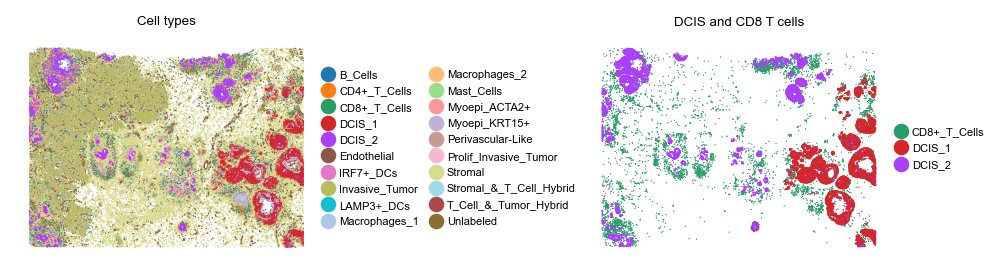

In [16]:
# 12. Fig. 5d: Xenium cell types and the DCIS / CD8 T cell subset (03_xenium_platform cells 14-15)
fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.6), gridspec_kw=dict(wspace=0.9))
sq.pl.spatial_scatter(
    adata_xe,
    color="Cluster",
    ax=axes[0],
    frameon=False,
    legend_fontsize=5,
    title="Cell types",
    linewidths=0,
    shape=None,
)
sq.pl.spatial_scatter(
    adata_xe,
    color="Cluster",
    groups=["DCIS_1", "DCIS_2", "CD8+_T_Cells"],
    ax=axes[1],
    frameon=False,
    legend_fontsize=5,
    title="DCIS and CD8 T cells",
    linewidths=0,
    shape=None,
)
sc.settings._vector_friendly = False
set_box_ratio(fig)
plt.savefig(figure_dir + "Fig5d_xenium_cell_types.pdf", bbox_inches="tight")
plt.show()
platform_map_table(adata_xe, ["Cluster"]).to_csv(source_dir + "Fig5d_xenium_cell_types.csv")

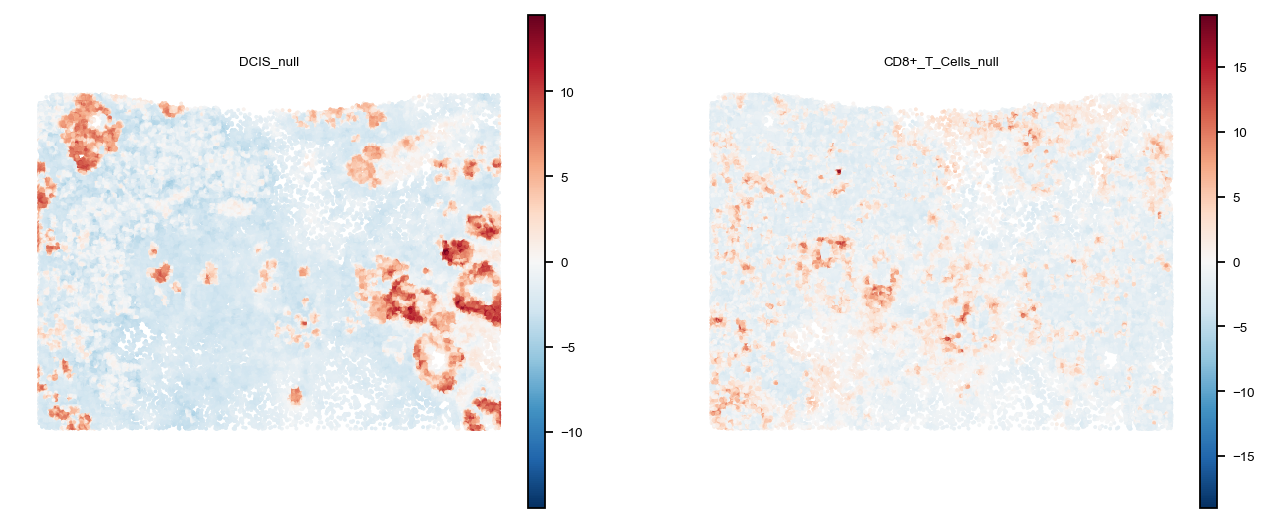

In [17]:
# 13. Fig. 5d: Xenium score maps (DCIS, CD8 T cell)
keys = [method_keys[m].format(sig=sig, suffix="") for sig in signatures_xe for m in colours]

em.pl.spatial_enrichmap(
    adata_xe,
    score_key=keys,
    ncols=3,
    save=f"Fig5d_xenium_score_maps.pdf",
    shape=None,
)

platform_map_table(adata_xe, keys).to_csv(source_dir + "Fig5d_xenium_score_maps.csv")

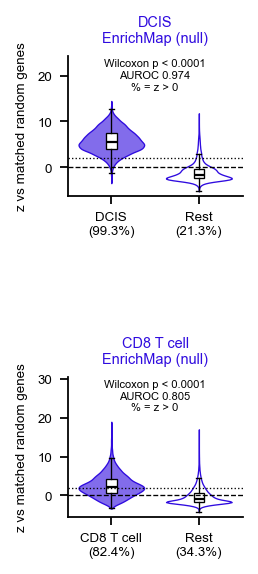

In [18]:
# 15. Fig. 5e: Xenium score distributions, ground truth vs rest
rows_e = [
    ("DCIS", "DCIS", is_dcis, {m: S("xenium", m, "DCIS") for m in colours}, P("xenium", "DCIS"), None),
    ("CD8 T cell", "CD8 T cell", is_cd8, {m: S("xenium", m, "CD8+_T_Cells") for m in colours}, P("xenium", "CD8+_T_Cells"), None),
]
violins = platform_plot_violins(rows_e, colours, call_rule)
set_box_ratio(plt.gcf())
plt.savefig(figure_dir + "Fig5e_xenium_violins.pdf", bbox_inches="tight")
plt.show()
violins.index = adata_xe.obs_names
violins.to_csv(source_dir + "Fig5e_xenium_violins.csv")

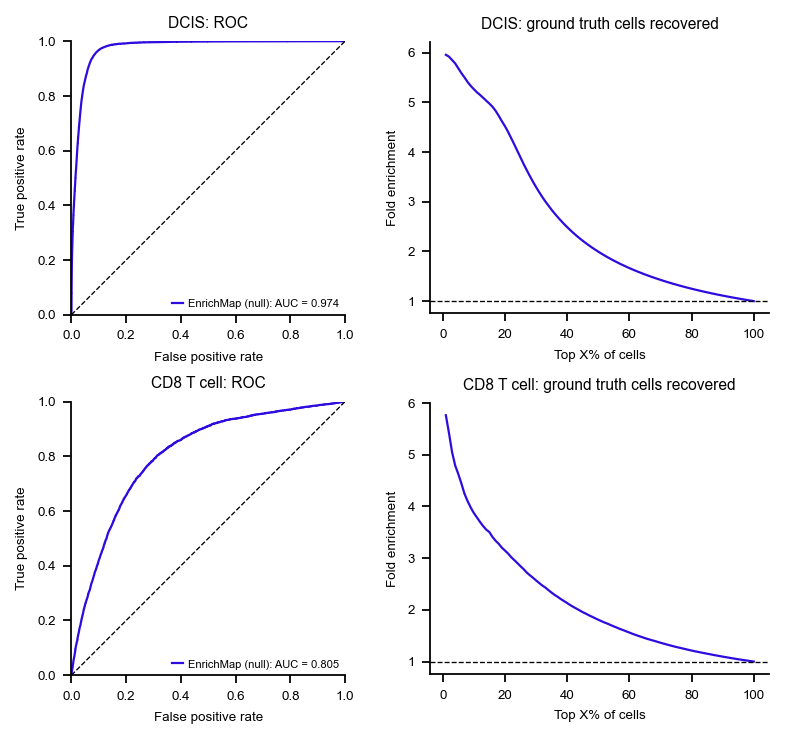

In [19]:
# 16. Fig. 5f: Xenium ROC and fold enrichment
curves = platform_plot_roc([(title, y, scores) for title, _, y, scores, _, _ in rows_e], colours)
set_box_ratio(plt.gcf())
plt.savefig(figure_dir + "Fig5f_xenium_roc_enrichment.pdf", bbox_inches="tight")
plt.show()
curves.to_csv(source_dir + "Fig5f_xenium_roc_enrichment.csv", index=False)

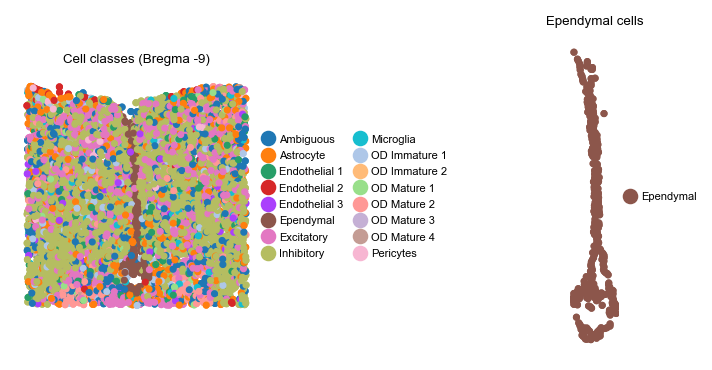

In [20]:
# 17. Fig. 5g: MERFISH Bregma -9 cell classes and ependymal cells (04_merfish_platform cells 8-9)
adata_mf9 = sc.AnnData(
    obs=adata_mf.obs[bregma9],
    obsm={"spatial": xy_mf[bregma9]},
    uns={"Cell_class_colors": adata_mf.uns["Cell_class_colors"]},
)
fig, axes = plt.subplots(1, 2, figsize=(5.6, 2.6), gridspec_kw=dict(wspace=0.9))
sq.pl.spatial_scatter(
    adata_mf9,
    color="Cell_class",
    ax=axes[0],
    frameon=False,
    legend_fontsize=5,
    title="Cell classes (Bregma -9)",
    shape=None,
)
sq.pl.spatial_scatter(
    adata_mf9,
    color="Cell_class",
    groups=["Ependymal"],
    ax=axes[1],
    frameon=False,
    legend_fontsize=5,
    title="Ependymal cells",
    shape=None,
)
set_box_ratio(fig)
plt.savefig(figure_dir + "Fig5g_merfish_cell_classes.pdf", bbox_inches="tight")
plt.show()
platform_map_table(adata_mf9, ["Cell_class"]).to_csv(source_dir + "Fig5g_merfish_cell_classes.csv")

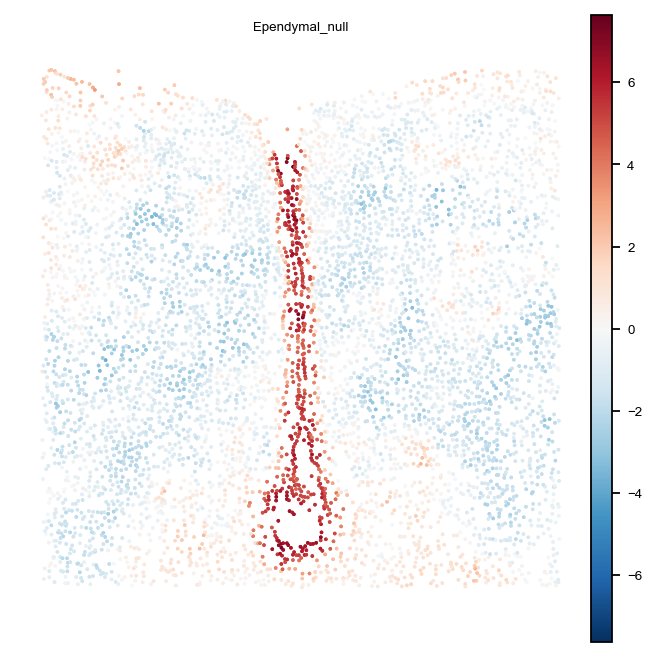

In [21]:
# 18. Fig. 5h: MERFISH ependymal score maps (Bregma -9; per-section scoring), centred at 0 and uncentred
keys = [method_keys[m].format(sig="Ependymal", suffix="") for m in colours]
em.pl.spatial_enrichmap(
    adata_mf9, score_key=keys, ncols=3, save=f"Fig5h_merfish_score_maps.pdf",
    shape=None,
)
platform_map_table(adata_mf9, keys).to_csv(source_dir + "Fig5h_merfish_score_maps.csv")

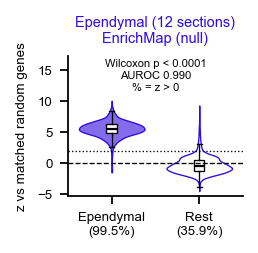

In [22]:
# 19. Fig. 5i: MERFISH score distributions (all 12 sections; per-section scoring)
rows_i = [("Ependymal (12 sections)", "Ependymal", is_ep, {m: S("merfish_batch", m, "Ependymal") for m in colours}, P("merfish_batch", "Ependymal"), None)]
violins = platform_plot_violins(rows_i, colours, call_rule)
set_box_ratio(plt.gcf())
plt.savefig(figure_dir + "Fig5i_merfish_violins.pdf", bbox_inches="tight")
plt.show()
violins.index = adata_mf.obs_names
violins.to_csv(source_dir + "Fig5i_merfish_violins.csv")

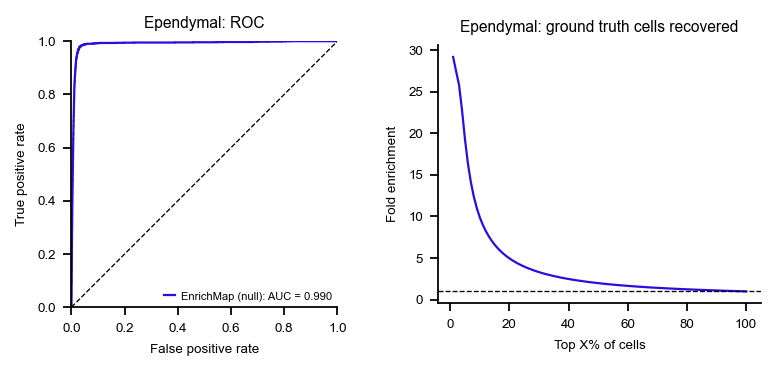

In [23]:
# 20. Fig. 5j: MERFISH ROC and fold enrichment (per-section scoring)
curves = platform_plot_roc([("Ependymal", is_ep, {m: S("merfish_batch", m, "Ependymal") for m in colours})], colours)
set_box_ratio(plt.gcf())
plt.savefig(figure_dir + "Fig5j_merfish_roc_enrichment.pdf", bbox_inches="tight")
plt.show()
curves.to_csv(source_dir + "Fig5j_merfish_roc_enrichment.csv", index=False)

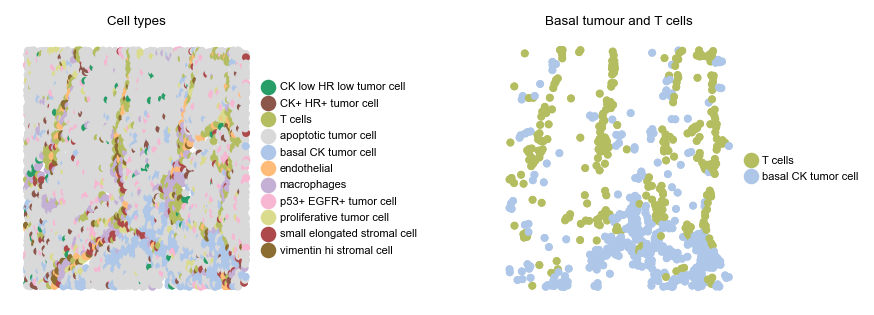

In [24]:
# 21. Fig. 5k-l: IMC cell types and the basal tumour / T cell subset (10_masscytometry_platform_deg cells 12-13)
# apoptotic tumour cells in light grey, as in the published figure
cats = list(adata_imc.obs["cell type"].cat.categories)
adata_imc.uns["cell type_colors"] = [
    "#d9d9d9" if c == "apoptotic tumor cell" else col
    for c, col in zip(cats, adata_imc.uns["cell type_colors"])
]
fig, axes = plt.subplots(1, 2, figsize=(5.8, 2.6), gridspec_kw=dict(wspace=1.0))
sq.pl.spatial_scatter(
    adata_imc,
    color="cell type",
    ax=axes[0],
    frameon=False,
    legend_fontsize=5,
    title="Cell types",
    shape=None,
)
sq.pl.spatial_scatter(
    adata_imc,
    color="cell type",
    groups=["basal CK tumor cell", "T cells"],
    ax=axes[1],
    frameon=False,
    legend_fontsize=5,
    title="Basal tumour and T cells",
    shape=None,
)
set_box_ratio(fig)
plt.savefig(
    figure_dir + "Fig5kl_imc_cell_types.pdf", bbox_inches="tight"
)
plt.show()
platform_map_table(adata_imc, ["cell type"]).to_csv(
    source_dir + "Fig5kl_imc_cell_types.csv"
)

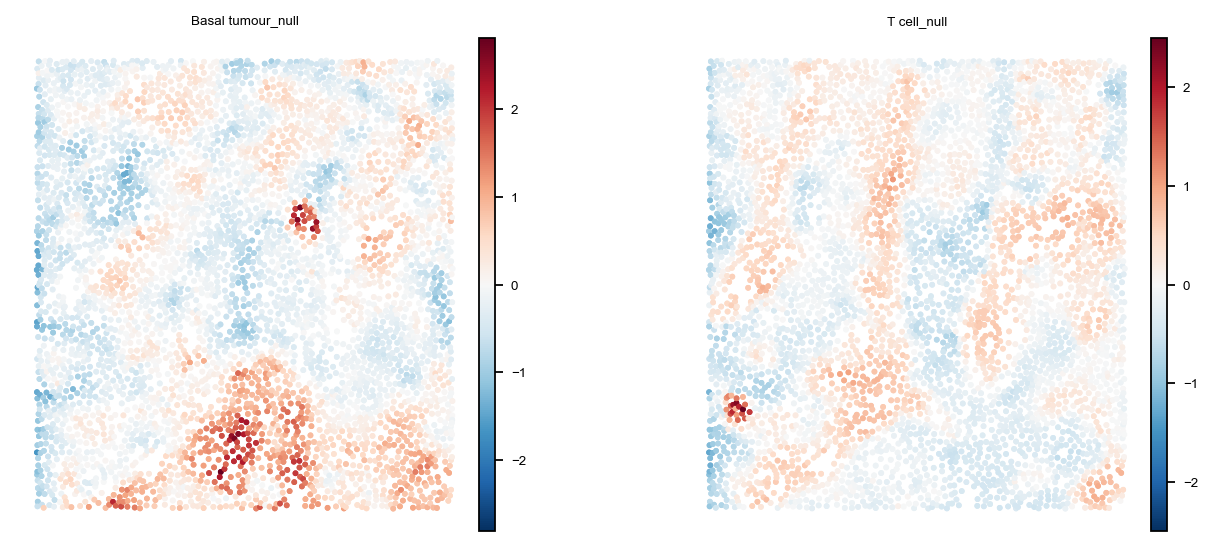

In [27]:
# 22. Fig. 5m: IMC score maps (basal tumour, T cell), centred at 0 and uncentred
keys = [method_keys[m].format(sig=sig, suffix="") for sig in signatures_imc for m in colours]
em.pl.spatial_enrichmap(
    adata_imc,
    score_key=keys,
    ncols=3,
    save=f"Fig5m_imc_score_maps.pdf",
    shape=None,
    size=10
)
platform_map_table(adata_imc, keys).to_csv(source_dir + "Fig5m_imc_score_maps.csv")

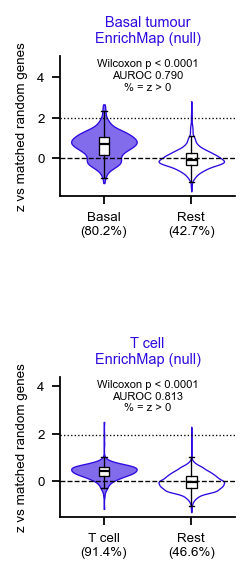

In [28]:
# 23. Fig. 5n: IMC score distributions, target vs rest
rows_n = [
    ("Basal tumour", "Basal", is_basal, {m: S("imc", m, "Basal tumour") for m in colours}, P("imc", "Basal tumour"), None),
    ("T cell", "T cell", is_t, {m: S("imc", m, "T cell") for m in colours}, P("imc", "T cell"), None),
]
violins = platform_plot_violins(rows_n, colours, call_rule)
set_box_ratio(plt.gcf())
plt.savefig(figure_dir + "Fig5n_imc_violins.pdf", bbox_inches="tight")
plt.show()
violins.index = adata_imc.obs_names
violins.to_csv(source_dir + "Fig5n_imc_violins.csv")